In [2]:
import numpy as np
import scipy.stats as stats
import pandas as pd

### Question a

##### Compute X

In [3]:
def compute_X():
    X = pd.Series(np.random.beta(4, 2, 100)).sum()
    return X
compute_X()

np.float64(68.86138036273432)

### Question b

##### Run the simulation 100,000 times

In [4]:
result = pd.Series([compute_X() for _ in range(100_000)])

##### Compute the probability for a given value

In [5]:
def compute_P(n):
    P = result.where(round(result, 0) == n).count() / result.size
    return P

##### Compute the probability for each given value

In [6]:
p1 = pd.DataFrame([{'n': n, 'Probability': compute_P(n)} for n in range(60, 76)])
p1

,n,Probability
0,60,0.00032
1,61,0.00183
2,62,0.00851
3,63,0.02739
4,64,0.07411
5,65,0.14298
6,66,0.20649
7,67,0.21822
8,68,0.17051
9,69,0.09528


##### Draw the bar graph of the result

<Axes: xlabel='n'>

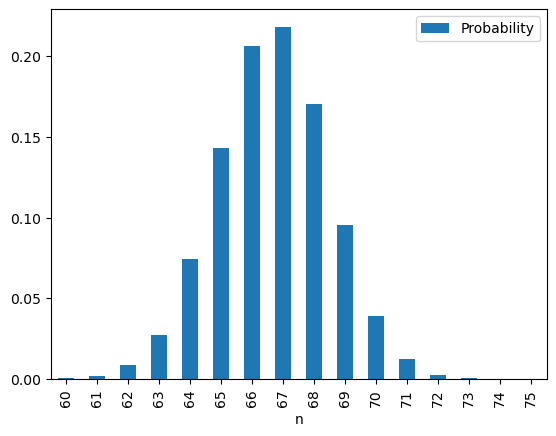

In [7]:
p1.plot.bar(x='n', y='Probability')

### Question c

Let $X_i$ be the $i$ th random variable chosen from $Beta(4, 2)$ distribution. $X$ is the sum of $X_i$, where $i$ ranges from $1$ to $100$. According to the central limit therom, the sum of random variables independently chosen from the same distribution follows a normal distribution: As $n \rightarrow \infty$, $\sum_{i = 1}^nX_i \sim N(n\mu, n\sigma^2)$. In this question, $n = 100$, and therefore we can approximate the distribution of $X$ is $X \sim N(\frac{200}{3}, \frac{200}{63})$

### Question d

##### Calculate the probability with the approximated distribution

In [8]:
p2 = stats.norm.cdf(70.5, 200/3, 200/63) - stats.norm.cdf(69.5, 200/3, 200/63)
p2

np.float64(0.07244267384667957)

##### Calculate the probability with the result of simulations

In [9]:
p3 = 0
for idx, row in p1.iterrows():
    if (69.5 < row['n']) & (row['n'] < 70.5):
        p3 += row['Probability']
p3

np.float64(0.03898)

##### Note:
1. series.where() computed on the series or DataFrame returns boolean Series/DataFrame or array

2. In Pandas, the count() function is used to get number of non-NA/null observations in the Series

3. Commonly, we use Python dictionary to create Pandas dataframe

4. Use DataFrame.plot.bar to plot the bar chart, and use, x and y to specify the x and y axis

5. Use DataFrame.iterrows() to iterate rows of the DataFrame